<a href="https://colab.research.google.com/github/hasanjim-dev/ml-learning/blob/main/model-evaluation/model_evaluation_metrics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Import Libraries

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report,
    roc_curve, roc_auc_score, RocCurveDisplay,
    precision_recall_curve
)

Load Dataset

In [3]:
data = sns.load_dataset('titanic')
data.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


Data Cleaning

In [4]:
data = data[['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked']].copy()

data['age'] = data['age'].fillna(data['age'].median())
data['embarked'] = data['embarked'].fillna(data['embarked'].mode()[0])

data['sex'] = LabelEncoder().fit_transform(data['sex'])
data['embarked'] = LabelEncoder().fit_transform(data['embarked'])

data.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked
0,0,3,1,22.0,1,0,7.2500,2
1,1,1,0,38.0,1,0,71.2833,0
2,1,3,0,26.0,0,0,7.9250,2
3,1,1,0,35.0,1,0,53.1000,2
4,0,3,1,35.0,0,0,8.0500,2


Split ও Scale

In [5]:
X = data.drop('survived', axis=1)
y = data['survived']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

2 Model train

In [6]:
log_model = LogisticRegression(random_state=42)
log_model.fit(X_train_scaled, y_train)

rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

y_pred_log = log_model.predict(X_test_scaled)
y_pred_rf = rf_model.predict(X_test)

Confusion Matrix (TP, FP, TN, FN)

In [7]:
cm = confusion_matrix(y_test, y_pred_log)
print(cm)

[[97 13]
 [23 46]]


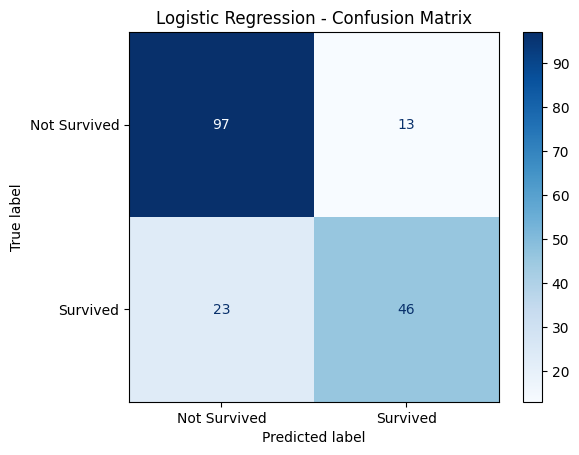

In [8]:
ConfusionMatrixDisplay(cm, display_labels=['Not Survived', 'Survived']).plot(cmap='Blues')
plt.title('Logistic Regression - Confusion Matrix')
plt.show()

In [9]:
# TN, FP, FN, TP আলাদা করা
TN, FP, FN, TP = cm.ravel()

print("TN (সঠিকভাবে বলা: বাঁচেনি):", TN)
print("FP (ভুল করে বলা: বেঁচেছে):", FP)
print("FN (ভুল করে বলা: বাঁচেনি):", FN)
print("TP (সঠিকভাবে বলা: বেঁচেছে):", TP)

TN (সঠিকভাবে বলা: বাঁচেনি): 97
FP (ভুল করে বলা: বেঁচেছে): 13
FN (ভুল করে বলা: বাঁচেনি): 23
TP (সঠিকভাবে বলা: বেঁচেছে): 46


Precision ও Recall

In [10]:

precision_manual = TP / (TP + FP)
recall_manual = TP / (TP + FN)

print("Precision (manual):", round(precision_manual, 4))
print("Recall (manual):", round(recall_manual, 4))

Precision (manual): 0.7797
Recall (manual): 0.6667


In [11]:
# sklearn দিয়ে মিলিয়ে দেখা
print("Precision (sklearn):", round(precision_score(y_test, y_pred_log), 4))
print("Recall (sklearn):", round(recall_score(y_test, y_pred_log), 4))

Precision (sklearn): 0.7797
Recall (sklearn): 0.6667


F1 Score

In [12]:

f1_manual = 2 * (precision_manual * recall_manual) / (precision_manual + recall_manual)
print("F1 (manual):", round(f1_manual, 4))
print("F1 (sklearn):", round(f1_score(y_test, y_pred_log), 4))

F1 (manual): 0.7188
F1 (sklearn): 0.7188


In [13]:
print(classification_report(y_test, y_pred_log, target_names=['Not Survived', 'Survived']))

              precision    recall  f1-score   support

Not Survived       0.81      0.88      0.84       110
    Survived       0.78      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.79      0.77      0.78       179
weighted avg       0.80      0.80      0.80       179



In [14]:
# একটা "বোকা" মডেল: সবাইকে বলে "বাঁচেনি"
y_dummy = np.zeros(len(y_test), dtype=int)

print("Dummy Accuracy:", round(accuracy_score(y_test, y_dummy), 4))
print("Dummy Recall:", recall_score(y_test, y_dummy))
print("Dummy F1:", f1_score(y_test, y_dummy))

Dummy Accuracy: 0.6145
Dummy Recall: 0.0
Dummy F1: 0.0


Precision & Recall - (Threshold)

In [15]:
y_prob = log_model.predict_proba(X_test_scaled)[:, 1]

for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    y_pred_t = (y_prob >= t).astype(int)
    print(f"Threshold {t}: "
          f"Precision={precision_score(y_test, y_pred_t):.3f}, "
          f"Recall={recall_score(y_test, y_pred_t):.3f}, "
          f"F1={f1_score(y_test, y_pred_t):.3f}")

Threshold 0.3: Precision=0.671, Recall=0.797, F1=0.728
Threshold 0.4: Precision=0.746, Recall=0.768, F1=0.757
Threshold 0.5: Precision=0.780, Recall=0.667, F1=0.719
Threshold 0.6: Precision=0.848, Recall=0.565, F1=0.678
Threshold 0.7: Precision=0.914, Recall=0.464, F1=0.615


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 2476 (\N{BENGALI LETTER BA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Matplotlib currently does not support Bengali natively.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 2470 (\N{BENGALI LETTER DA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 2482 (\N{BENGALI LETTER LA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 2494 (\N{BENGALI VOWEL SIGN AA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dis

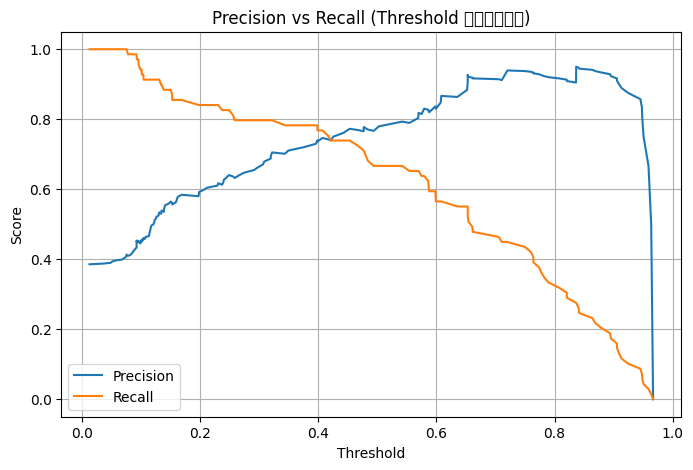

In [16]:
# Precision-Recall Curve
precisions, recalls, thresholds = precision_recall_curve(y_test, y_prob)

plt.figure(figsize=(8, 5))
plt.plot(thresholds, precisions[:-1], label='Precision')
plt.plot(thresholds, recalls[:-1], label='Recall')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Precision vs Recall (Threshold বদলালে)')
plt.legend()
plt.grid(True)
plt.show()

ROC Curve

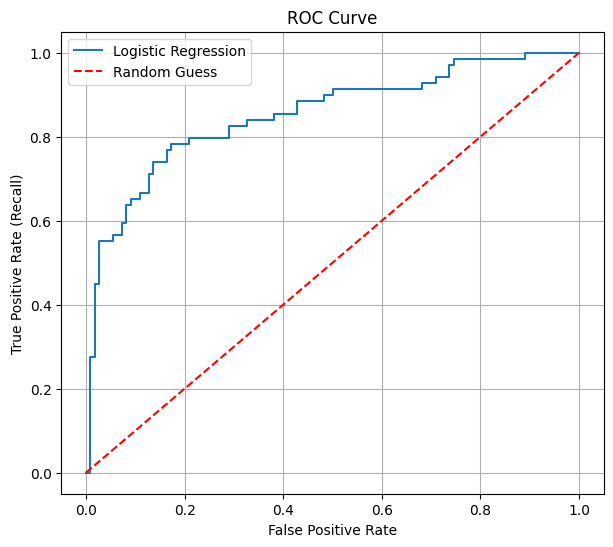

In [17]:
fpr, tpr, roc_thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, label='Logistic Regression')
plt.plot([0, 1], [0, 1], 'r--', label='Random Guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.title('ROC Curve')
plt.legend()
plt.grid(True)
plt.show()

ROC-AUC Score

In [18]:
auc_log = roc_auc_score(y_test, y_prob)
print("Logistic Regression AUC:", round(auc_log, 4))

Logistic Regression AUC: 0.8519


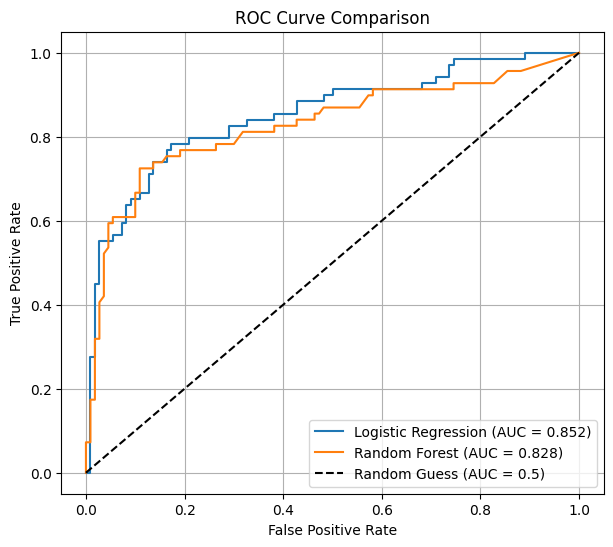

In [19]:
# দুটো মডেলের ROC একসাথে
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]
auc_rf = roc_auc_score(y_test, y_prob_rf)

fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, label=f'Logistic Regression (AUC = {auc_log:.3f})')
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {auc_rf:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random Guess (AUC = 0.5)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend()
plt.grid(True)
plt.show()

Metrics suggestion

In [20]:
metrics_df = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest'],
    'Accuracy': [accuracy_score(y_test, y_pred_log), accuracy_score(y_test, y_pred_rf)],
    'Precision': [precision_score(y_test, y_pred_log), precision_score(y_test, y_pred_rf)],
    'Recall': [recall_score(y_test, y_pred_log), recall_score(y_test, y_pred_rf)],
    'F1': [f1_score(y_test, y_pred_log), f1_score(y_test, y_pred_rf)],
    'ROC-AUC': [auc_log, auc_rf]
})
metrics_df.round(4)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.7989,0.7797,0.6667,0.7188,0.8519
1,Random Forest,0.8268,0.8065,0.7246,0.7634,0.8277
